# Куда уходит время на буровой

**Вопрос.** Сутки работы морской буровой стоят сотни тысяч долларов, поэтому главный ресурс проекта — время станка. На что оно уходит, где теряется и какие потери можно убрать?

**Данные.** Суточные буровые рапорты месторождения Volve в Северном море, которые оператор Equinor открыл в 2018 году: 1 758 рапортов по 26 стволам, 23 447 операций с временем начала и конца, кодом операции, отметкой об успехе и комментарием супервайзера.

**Что сделано.** Рапорты разобраны в базу DuckDB, время разделено на работу по программе, непроизводительное время (НПВ) и ожидание погоды. Причины потерь восстановлены по тексту комментариев, потому что в коде операции 40% потерь записаны как «прочее». Разброс оценён бутстрэпом.

In [1]:
import sys
sys.path.insert(0, "../src")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from volve import analysis as A
from volve import viz

viz.setup()
pd.set_option("display.float_format", "{:,.1f}".format)

reports, ops, wellbores = A.load()
ops = A.add_causes(A.add_campaigns(reports, ops))
days = A.daily(ops)
print(f"рапортов {len(reports):,}, операций {len(ops):,}, стволов {ops.wellbore.nunique()}, "
      f"часов {ops.hours.sum():,.0f} ({ops.hours.sum() / 24:,.0f} суток станка)")

рапортов 1,758, операций 23,447, стволов 26, часов 39,395 (1,641 суток станка)


## 1. Данные и их качество

Прежде чем считать, проверяю, можно ли данным верить.

In [2]:
per_report = ops.groupby("report_id").hours.sum()
quality = pd.Series({
    "рапортов с полными 24 часами, %": (per_report.round(2) == 24).mean() * 100,
    "покрытие времени операциями, %": per_report.sum() / (len(per_report) * 24) * 100,
    "операций без кода, %": ops.activity_group.isna().mean() * 100,
    "операций без комментария, %": ops.comment.isna().mean() * 100,
    "рапортов без забоя, %": reports.md.isna().mean() * 100,
    "рапортов без диаметра ствола, %": reports.hole_in.isna().mean() * 100,
})
display(quality.to_frame("значение"))
display(wellbores.assign(era=wellbores.era).groupby("era").agg(стволов=("wellbore", "count"), рапортов=("reports", "sum"),
        станки=("rig", lambda s: ", ".join(sorted(set(s))))))

,значение
"рапортов с полными 24 часами, %",87.4
"покрытие времени операциями, %",93.8
"операций без кода, %",0.0
"операций без комментария, %",0.0
"рапортов без забоя, %",18.8
"рапортов без диаметра ствола, %",56.3


,стволов,рапортов,станки
era,,,
разведка 1992–1998,5,375,"BYFORD DOLPHIN, TREASURE PROSPECT"
разработка 2007–2016,21,1384,MÆRSK INSPIRER


**Что видно.**

- Время покрыто хорошо: 87% рапортов расписаны на полные 24 часа. Неполные сутки приходятся на начало и конец работ на стволе.
- Один рапорт датирован 1980 годом, хотя ствол бурили в 1997-м. Это ошибка исходника, рапорт исключён.
- Диаметр ствола указан меньше чем в половине рапортов, поэтому сравнение по секциям считаю только там, где он есть.
- В данных две разные эпохи: разведочные скважины 1992–1998 годов с полупогружных установок и эксплуатационное бурение 2007–2016 годов с самоподъёмной установки Mærsk Inspirer. Сравнивать их в одной куче нельзя, дальше они идут раздельно.
- Ствол живёт долго: бурение, заканчивание, ремонты и ликвидация в 2016 году. Поэтому рапорты разбиты на **кампании** — непрерывные серии с перерывом не больше 30 дней. Тип кампании определяет группа операций с наибольшим временем.

## 2. Баланс времени

Правило разметки записано в `sql/marts.sql`:

- **НПВ** — операция из группы `interruption` или операция, которую супервайзер отметил как неуспешную;
- **ожидание погоды** — отдельно: на шельфе оно от подрядчика не зависит;
- остальное — работа по программе.

time_class,непроизводительное время,работа по программе,ожидание погоды
era,,,
разведка 1992–1998,31.2,63.7,5.1
разработка 2007–2016,12.8,82.4,4.8
всего,16.8,78.3,4.9


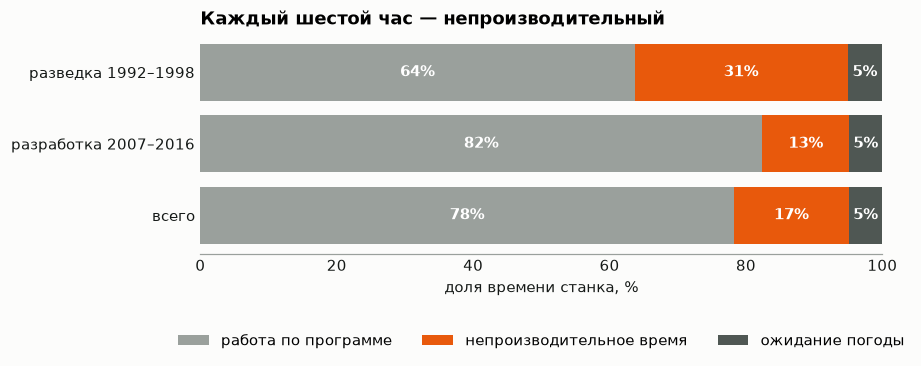

In [3]:
balance = ops.groupby(["era", "time_class"]).hours.sum().unstack()
balance.loc["всего"] = balance.sum()
share = balance.div(balance.sum(axis=1), axis=0) * 100
display(share.rename(columns=A.CLASS_RU))

fig, ax = plt.subplots(figsize=(8, 2.6))
left = np.zeros(len(share))
for cls in ("productive", "npt", "weather"):
    ax.barh(share.index, share[cls], left=left, color=viz.CLASS_COLORS[cls], label=A.CLASS_RU[cls])
    for y, (v, l) in enumerate(zip(share[cls], left)):
        if v > 4:
            ax.text(l + v / 2, y, f"{v:.0f}%", ha="center", va="center", color="white", fontweight="bold")
    left += share[cls].to_numpy()
ax.set(xlim=(0, 100), xlabel="доля времени станка, %", title="Каждый шестой час — непроизводительный")
ax.invert_yaxis(); ax.grid(False); ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.3))
viz.save(fig, "01_balance.png"); plt.show()

In [4]:
for era, g in days.groupby("era"):
    p, lo, hi = A.npt_share_ci(g)
    print(f"{era}: НПВ {p:.1%} [{lo:.1%}; {hi:.1%}], суток {len(g)}")
d, lo, hi = A.diff_ci(days[days.era.str.startswith("разведка")], days[days.era.str.startswith("разработка")])
print(f"разница: {d * 100:.1f} п.п. [{lo * 100:.1f}; {hi * 100:.1f}]")

разведка 1992–1998: НПВ 31.2% [27.2%; 35.4%], суток 373
разработка 2007–2016: НПВ 12.8% [11.5%; 14.0%], суток 1377


разница: 18.4 п.п. [14.1; 22.8]


**Вывод.** За всё время НПВ — 16,8% времени станка, ещё 4,9% — погода. В разведке потери в 2,4 раза выше, чем в эксплуатационном бурении: 31% против 13%, разница 18 п.п. с 95% интервалом от 14 до 23 п.п. Интервал посчитан бутстрэпом по суткам; соседние сутки на одном стволе зависимы, поэтому настоящий разброс шире, но разница такого размера случайной не выглядит.

## 3. Причины потерь: что прячется в «прочем»

В рапортах у простоя есть код причины. Проблема в том, что самый большой код — `interruption -- other`.

In [5]:
npt = ops[ops.time_class == "npt"]
by_code = (npt.assign(код=np.where(npt.activity_group == "interruption", npt.activity, "сбой в плановой операции"))
           .groupby("код").hours.sum().sort_values(ascending=False))
display((by_code / by_code.sum() * 100).head(6).to_frame("доля НПВ, %"))

,"доля НПВ, %"
код,
other,40.4
repair,18.3
sidetrack,8.9
fish,8.6
maintain,8.5
wait,7.9


40% потерь записаны как «прочее», ещё 18% — как «ремонт» без уточнения, что именно ломалось. С таким кодом управлять нечем. Причину восстанавливаю по комментарию супервайзера: 14 правил по ключевым словам в `analysis.TEXT_RULES`, первое совпадение побеждает.

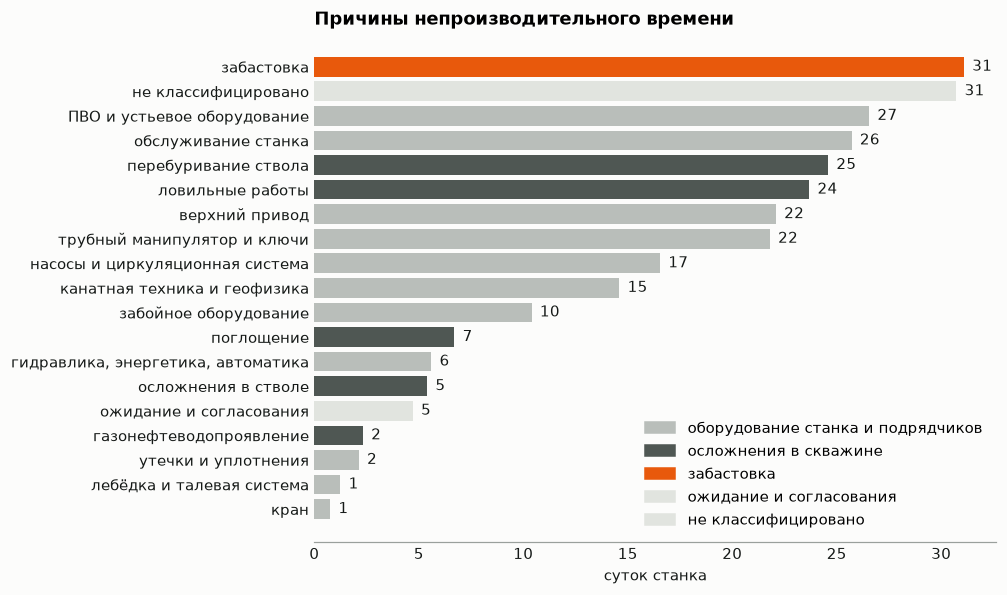

era,разведка 1992–1998,разработка 2007–2016
group,,
забастовка,27.0,0.0
не классифицировано,7.0,14.0
оборудование станка и подрядчиков,24.0,74.0
ожидание и согласования,0.0,3.0
осложнения в скважине,41.0,10.0


не классифицировано после разбора текста: 11% НПВ


In [6]:
causes = npt.groupby("cause").hours.sum().sort_values()
groups = causes.index.map(A.cause_group)
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(causes.index, causes / 24, color=[viz.GROUP_COLORS[g] for g in groups])
for y, v in enumerate(causes / 24):
    ax.text(v + 0.4, y, f"{v:.0f}", va="center", color=viz.INK)
ax.set(xlabel="суток станка", title="Причины непроизводительного времени")
ax.grid(axis="y", visible=False)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in viz.GROUP_COLORS.values()], labels=list(viz.GROUP_COLORS), loc="lower right")
viz.save(fig, "02_causes.png"); plt.show()

by_group = npt.assign(group=npt.cause.map(A.cause_group)).groupby(["group", "era"]).hours.sum().unstack().fillna(0)
display((by_group / by_group.sum() * 100).round(0))
print(f"не классифицировано после разбора текста: {causes['не классифицировано'] / causes.sum():.0%} НПВ")

**Что нашлось.**

- **Забастовка.** Крупнейшая «прочая» причина — забастовка профсоюза нефтяников в сентябре 1997 года: 746 часов, или 31 сутки простоя на одном стволе. Это 11% всех потерь за 24 года, и в кодах её не видно совсем. Без неё НПВ в разведке — 25%, а не 31%.
- **Разведка и разработка теряют время по-разному.** В разведке 41% потерь — осложнения в скважине: перебуривание стволов, ловильные работы, поглощения. В эксплуатационном бурении геология уже известна, и 74% потерь даёт оборудование станка и подрядчиков, а осложнения — только 10%.
- **Три узла станка** — ПВО и устьевое оборудование, верхний привод, трубный манипулятор — дают четверть всех потерь.
- Без причины осталось 11% НПВ против исходных 40%.

## 4. Потери — это редкие крупные события

Подряд идущие операции НПВ на одном стволе объединяю в событие.

событий 945, медиана 1.75 ч; 10% крупнейших дают 66% потерь; дольше суток — 45 событий, 53% потерь


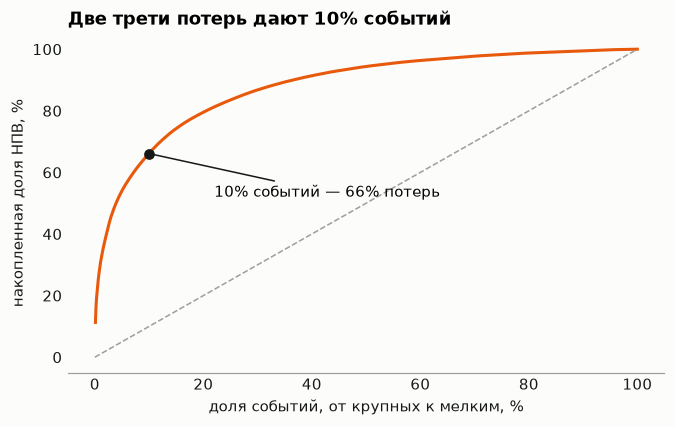

,wellbore,start,суток,cause,что
0,15/9-19 A,1997-09-03 13:00:00,31.2,забастовка,OPERATIONS SUSPENDED DUE TO OFS STRIKE.
1,15/9-19 ST2,1992-12-18 12:00:00,14.1,перебуривание ствола,"DRILLED/SURVEYED 12 1/4"" HOLE FROM 1926M TO 22..."
2,15/9-19 B,1997-11-27 11:00:00,8.2,ловильные работы,FINISHED RIGGING UP ATLAS WIRELINE TO RUN BACK...
3,15/9-F-12,2008-01-05 14:00:00,5.8,трубный манипулятор и ключи,Waited for weather condtions to improve for re...
4,15/9-19 ST2,1993-01-04 15:00:00,5.6,перебуривание ствола,"DRILLED AND ORIENTATED 12 1/4"" HOLE FROM 3215M..."
5,15/9-F-11,2013-03-18 00:00:00,5.2,не классифицировано,Waited on cement.\n\nMeanwhile: changed encode...
6,15/9-F-11 T2,2013-03-24 17:30:00,4.4,обслуживание станка,Prepared for changing out fast-line sheave in ...
7,15/9-19 B,1997-11-14 15:30:00,3.9,поглощение,RIG REPAIR: REMOVED DAMAGED HEAD AND CYLINDER ...


In [7]:
ev = A.events(ops).sort_values("hours", ascending=False).reset_index(drop=True)
cum = ev.hours.cumsum() / ev.hours.sum()
top10 = cum.iloc[len(ev) // 10 - 1]
long = ev[ev.hours > 24]
print(f"событий {len(ev)}, медиана {ev.hours.median():.2f} ч; 10% крупнейших дают {top10:.0%} потерь; "
      f"дольше суток — {len(long)} событий, {long.hours.sum() / ev.hours.sum():.0%} потерь")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.arange(1, len(ev) + 1) / len(ev) * 100, cum * 100, color=viz.ACCENT, lw=2)
ax.plot([0, 100], [0, 100], color=viz.GREY, ls="--", lw=1)
ax.scatter([10], [top10 * 100], color=viz.INK, zorder=3)
ax.annotate(f"10% событий — {top10:.0%} потерь", (10, top10 * 100), (22, top10 * 100 - 14), arrowprops=dict(arrowstyle="-", color=viz.INK))
ax.set(xlabel="доля событий, от крупных к мелким, %", ylabel="накопленная доля НПВ, %", title="Две трети потерь дают 10% событий")
viz.save(fig, "03_events.png"); plt.show()

display(ev.head(8).assign(суток=lambda d: d.hours / 24, что=lambda d: d.comment.str.slice(0, 70))[["wellbore", "start", "суток", "cause", "что"]])

**Вывод.** Типичный простой короткий: медиана 1 час 45 минут. Но 10% событий дают 66% потерь, а 45 событий дольше суток — больше половины. Средний процент НПВ поэтому плохо описывает риск: сроки срывают не сотни мелких остановок, а несколько аварий. Отсюда практическое следствие: разбирать нужно в первую очередь крупные события, каждое по отдельности.

## 5. Где теряется время при бурении

Беру только кампании бурения эксплуатационных скважин (2007–2016, одна и та же установка) — их можно честно сравнивать между собой.

,секция,суток,НПВ,lo,hi
0,"36""",49,4.7,2.3,7.6
1,"26""",87,12.8,7.9,18.3
2,"17.5""",121,9.4,6.6,12.3
3,"12.25""",94,11.3,8.1,15.0
4,"8.5""",128,16.3,11.5,21.4


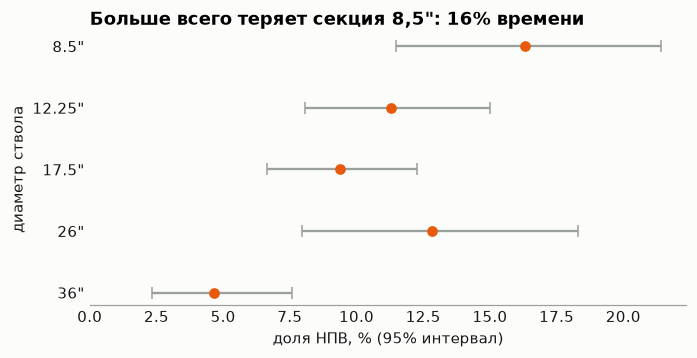

In [8]:
drill = days[(days.campaign_type == "бурение") & days.era.str.startswith("разработка")]
rows = []
for hole, g in drill.dropna(subset=["hole_in"]).groupby("hole_in"):
    if len(g) >= 30:
        p, lo, hi = A.npt_share_ci(g)
        rows.append(dict(секция=f'{hole:g}"', суток=len(g), НПВ=p * 100, lo=lo * 100, hi=hi * 100))
sec = pd.DataFrame(rows).iloc[::-1].reset_index(drop=True)
display(sec)

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.errorbar(sec["НПВ"], sec["секция"], xerr=[sec["НПВ"] - sec.lo, sec.hi - sec["НПВ"]], fmt="o", color=viz.ACCENT, ecolor=viz.GREY, capsize=4)
ax.set(xlabel="доля НПВ, % (95% интервал)", ylabel="диаметр ствола", title='Больше всего теряет секция 8,5": 16% времени', xlim=(0, None))
viz.save(fig, "04_sections.png"); plt.show()

кампаний 21, суток 711, из них НПВ 86; доля НПВ: медиана 9.1%, лучшая четверть — до 6.7%
если бы каждая кампания теряла не больше, чем лучшая четверть: −40 суток (5.7% времени бурения)


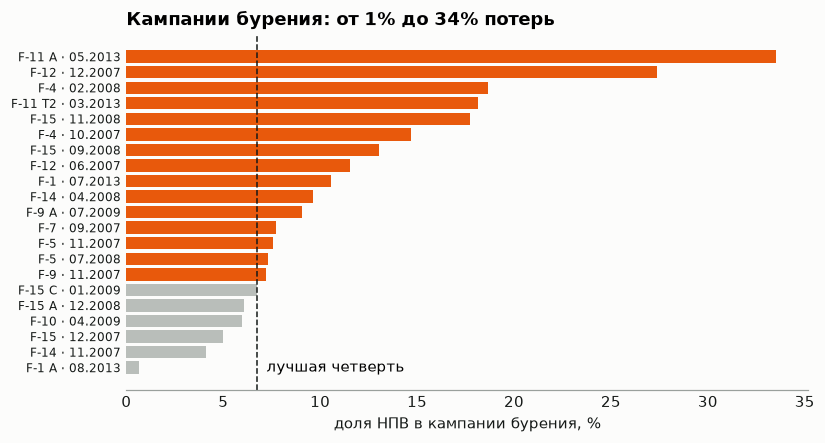

In [9]:
camp = A.campaigns(ops)
dev = camp[(camp.campaign_type == "бурение") & camp.era.str.startswith("разработка") & (camp.days >= 5)].sort_values("start")
target = dev.npt_share.quantile(0.25)
saving = ((dev.npt_share - target).clip(lower=0) * dev.hours).sum() / 24
print(f"кампаний {len(dev)}, суток {dev.days.sum():.0f}, из них НПВ {dev.npt_hours.sum() / 24:.0f}; "
      f"доля НПВ: медиана {dev.npt_share.median():.1%}, лучшая четверть — до {target:.1%}")
print(f"если бы каждая кампания теряла не больше, чем лучшая четверть: −{saving:.0f} суток ({saving / dev.days.sum():.1%} времени бурения)")

fig, ax = plt.subplots(figsize=(8, 4.2))
order = dev.sort_values("npt_share")
ax.barh(order.wellbore.str.replace("15/9-", "") + " · " + order.start.dt.strftime("%m.%Y"), order.npt_share * 100,
        color=np.where(order.npt_share > target, viz.ACCENT, viz.CALM))
ax.axvline(target * 100, color=viz.INK, ls="--", lw=1); ax.text(target * 100 + 0.5, 0, "лучшая четверть", va="center")
ax.set(xlabel="доля НПВ в кампании бурения, %", title="Кампании бурения: от 1% до 34% потерь")
ax.grid(axis="y", visible=False); ax.tick_params(axis="y", labelsize=8)
viz.save(fig, "05_campaigns.png"); plt.show()

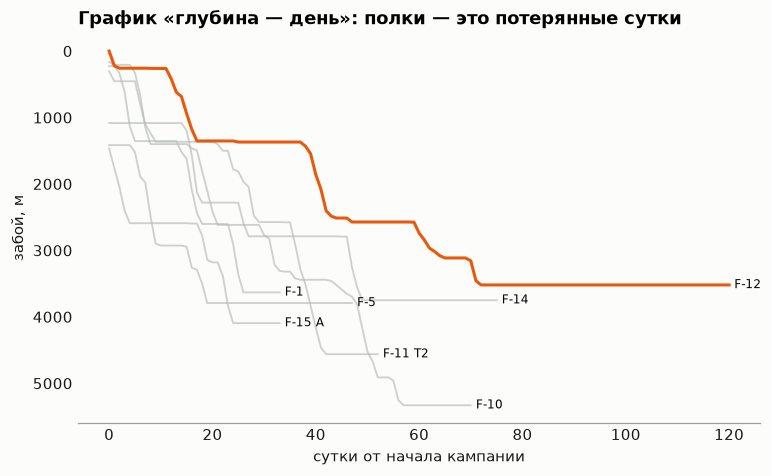

In [10]:
rep = reports.merge(ops[["report_id", "campaign", "campaign_type", "era"]].drop_duplicates(), on="report_id")
rep = rep[(rep.campaign_type == "бурение") & rep.era.str.startswith("разработка") & rep.md.notna()]
fig, ax = plt.subplots(figsize=(8, 4.6))
for (wb, c), g in rep.groupby(["wellbore", "campaign"]):
    g = g.sort_values("day_start")
    if g.md.max() < 3000 or g.md.min() > 1500:
        continue
    t = (g.day_start - g.day_start.min()).dt.days
    worst = wb in ("15/9-F-12", "15/9-F-4")
    ax.plot(t, g.md.cummax(), color=viz.ACCENT if worst else viz.CALM, lw=2 if worst else 1.2, alpha=1 if worst else 0.7)
    ax.text(t.iloc[-1] + 1, g.md.max(), wb.replace("15/9-", ""), fontsize=8, va="center")
ax.invert_yaxis(); ax.set(xlabel="сутки от начала кампании", ylabel="забой, м", title="График «глубина — день»: полки — это потерянные сутки")
viz.save(fig, "06_depth_day.png"); plt.show()

**Вывод.**

- Больше всего времени теряется в секции 8,5" — 16% против 9–13% в остальных. Интервалы с соседними секциями пересекаются, так что различие правдоподобное, но не доказанное: суток в каждой секции около сотни. Для буровика это ожидаемо (сложнее компоновка, выше цена ошибки), теперь у ожидания есть число и его погрешность.
- Разброс между кампаниями огромный: от 1% до 34% потерь на одной и той же установке.
- Оценка резерва: если бы каждая из 21 кампании теряла не больше, чем лучшая четверть (6,7%), бурение заняло бы на 40 суток меньше — 5,7% времени. Это верхняя граница организационного резерва, а не прогноз: часть потерь в худших кампаниях вызвана геологией.

## 6. Погода

Ожидание погоды в баланс НПВ не входит, но в график работ его нужно закладывать.

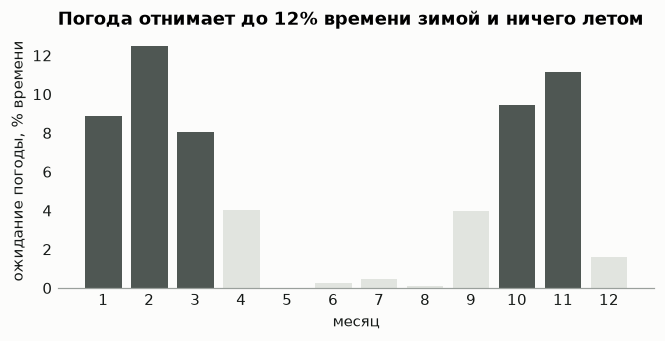

In [11]:
season = days.assign(month=days.day.dt.month).groupby("month").apply(lambda g: g.wow.sum() / g.hours.sum() * 100, include_groups=False)
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(season.index, season, color=np.where(season > 6, viz.WARN, viz.LIGHT))
ax.set(xticks=range(1, 13), xlabel="месяц", ylabel="ожидание погоды, % времени", title="Погода отнимает до 12% времени зимой и ничего летом")
ax.grid(axis="x", visible=False)
viz.save(fig, "07_weather.png"); plt.show()

**Вывод.** В октябре — марте погода отнимает 8–12% времени станка (кроме декабря, где в выборке всего 1,6%), с мая по август — меньше 1%. Операции, чувствительные к волнению (работа с ПВО, грузовые операции, канатные работы), выгоднее планировать на лето.

## 7. Итоги

1. **Каждый шестой час станка — непроизводительный** (16,8%), ещё 5% — погода. В разведке потери в 2,4 раза выше, чем в эксплуатационном бурении.
2. **Код причины в рапортах не работает:** 40% потерь записаны как «прочее». Разбор комментариев снизил неизвестную долю до 11% и вскрыл крупнейшее событие — забастовку на 31 сутки.
3. **В эксплуатационном бурении 74% потерь — оборудование**, а не геология. Четверть всех потерь дают три узла: ПВО, верхний привод, трубный манипулятор.
4. **Потери — это редкие крупные события:** 10% событий дают 66% НПВ.
5. **Резерв бурения — до 40 суток из 711** (5,7%), если подтянуть худшие кампании к уровню лучшей четверти.

**Что бы я рекомендовал оператору.**

- Ввести обязательный код узла оборудования для каждого простоя и запретить «прочее» дольше часа: без этого потери не видны.
- По каждому событию дольше суток делать разбор причин; их 45 за всё время, и они дают больше половины потерь.
- Сосредоточить профилактику на трёх узлах: ПВО, верхний привод, трубный манипулятор.
- Чувствительные к погоде работы планировать на май — август.

**Ограничения.** Причины по тексту размечены правилами, а не вручную: часть операций могла попасть не в свою категорию, 11% остались без причины. Интервалы бутстрэпа не учитывают зависимость соседних суток. Одно месторождение и три установки — выводы нельзя переносить на другие проекты без проверки. Стоимость суток в данных отсутствует, поэтому потери посчитаны во времени, а не в деньгах.